# d3 · Distillation vs training on the labels alone

**Knowledge distillation** (Hinton et al. 2015): the student is trained to match the teacher's softened output
distribution as well as the labels,

  loss = α · T² · KL( softmax(teacher / T) ‖ softmax(student / T) ) + (1 − α) · label loss.

The teacher's probabilities carry more than the label: *how* glioma-like a meningioma looks, which images are
ambiguous. T (temperature) softens them so that small probabilities still carry signal; α weighs teacher against
labels. The teacher sees exactly the same augmented batch as the student.

**Plan.**
1. Tune T ∈ {2, 4, 8} and α ∈ {0.5, 0.9} on two reference students from d2: the smallest with mean ≥ 0.95 and the
   smallest with mean ≥ 0.85 (the two floors). Highest mean (over both references) wins.
2. Train every d2 frontier architecture with that setting, and compare each with the same architecture trained on
   the labels only (d2): same seeds, same recipe, only the loss differs.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from dataclasses import replace
from lib import compress as C, dreport as R
from lib.train import RESULTS, build_model
from lib.data import ARTIFACTS
FRONT = json.loads((ARTIFACTS / "d2_frontier.json").read_text())
W = lambda w0: (w0, 2 * w0, 4 * w0, 8 * w0)
arch_cfg = lambda a, exp, name: R.student(exp, name, block=a["block"], kernel=a["kernel"], stem_kernel=a["kernel"], widths=W(a["w0"]))
TEACHER_ARCH = "single_k5_w16"
tsize = C.size_report(build_model(R.teacher_cfg(), 1))

def plain_runs(a):
    if a["name"] == TEACHER_ARCH:   # the teacher's own architecture trained on labels = c9
        return [dict(json.loads((RESULTS / "c9" / f"final_s{s}.json").read_text()), size=tsize) for s in R.SEEDS3]
    return R.run_seeds(arch_cfg(a, "d2", a["name"]))

plain = {a["name"]: plain_runs(a) for a in FRONT}
tp = R.table(plain)
refs = {}
for label, fl in R.FLOORS.items():
    k = R.pick(tp, fl)
    refs[label] = k if k is not None else tp.bal_acc.astype(float).idxmax()
print("d2 frontier:", list(plain)); print("reference students:", refs)

d2 frontier: ['dwsep_k5_w32', 'dwsep_k5_w8', 'dwsep_k5_w4', 'dwsep_k5_w2', 'dwsep_k3_w16', 'dwsep_k3_w8', 'dwsep_k3_w4', 'single_k5_w16']
reference students: {'high-performance': 'dwsep_k5_w32', 'tiny': 'dwsep_k5_w4'}


## 1. Temperature and weight

reference 'high-performance': dwsep_k5_w32


,kB,bal_acc,sd,tumor_auc,no_tumor_rec
labels only,207.1406,0.9643,0.0009,0.9979,0.9653
"T=2, a=0.5",207.1406,0.9645,0.0007,0.9960,0.9618
"T=2, a=0.9",207.1406,0.9604,0.0030,0.9966,0.9757
"T=4, a=0.5",207.1406,0.9642,0.0036,0.9972,0.9653
"T=4, a=0.9",207.1406,0.9646,0.0052,0.9972,0.9653
"T=8, a=0.5",207.1406,0.9599,0.0041,0.9958,0.9618
"T=8, a=0.9",207.1406,0.9629,0.0030,0.9966,0.9757


reference 'tiny': dwsep_k5_w4


,kB,bal_acc,sd,tumor_auc,no_tumor_rec
labels only,7.0938,0.8616,0.0049,0.9818,0.8820
"T=2, a=0.5",7.0938,0.8527,0.0098,0.9810,0.8368
"T=2, a=0.9",7.0938,0.8532,0.0103,0.9782,0.8715
"T=4, a=0.5",7.0938,0.8685,0.0086,0.9786,0.8819
"T=4, a=0.9",7.0938,0.8549,0.0240,0.9769,0.8542
"T=8, a=0.5",7.0938,0.8629,0.0141,0.9782,0.8611
"T=8, a=0.9",7.0938,0.8610,0.0219,0.9774,0.8958


,high-performance,tiny,mean of both
"T=2, a=0.5",0.9645,0.8527,0.9086
"T=2, a=0.9",0.9604,0.8532,0.9068
"T=4, a=0.5",0.9642,0.8685,0.9164
"T=4, a=0.9",0.9646,0.8549,0.9098
"T=8, a=0.5",0.9599,0.8629,0.9114
"T=8, a=0.9",0.9629,0.8610,0.9120


chosen: {'T': 4, 'alpha': 0.5}


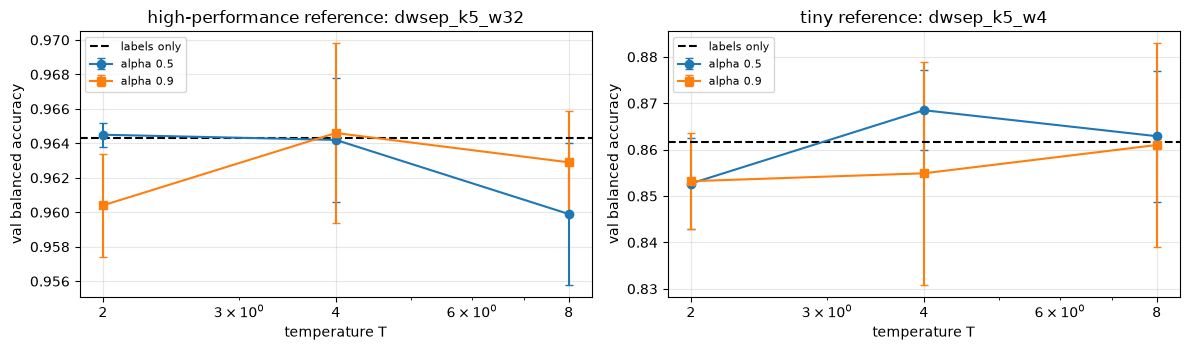

In [2]:
GRID = [(Tk, a) for Tk in [2, 4, 8] for a in [0.5, 0.9]]
arch = {a["name"]: a for a in FRONT}
sweep = {}
for label, ref in refs.items():
    sweep[label] = {"labels only": plain[ref]}
    for Tk, a in GRID:
        cfg = replace(arch_cfg(arch[ref], "d3", f"{ref}_kdT{Tk}a{a}"), extra={"kd": {"T": Tk, "alpha": a}})
        sweep[label][f"T={Tk}, a={a}"] = R.run_seeds(cfg)
tabs = {label: R.table(s) for label, s in sweep.items()}
for label, tt in tabs.items():
    print(f"reference '{label}': {refs[label]}"); display(tt[["kB", "bal_acc", "sd", "tumor_auc", "no_tumor_rec"]])
mean_kd = pd.concat({l: tt.bal_acc.astype(float) for l, tt in tabs.items()}, axis=1).drop("labels only")
mean_kd["mean of both"] = mean_kd.mean(axis=1)
display(mean_kd.round(4))
best = mean_kd["mean of both"].idxmax()
KD = dict(T=int(best.split(",")[0].split("=")[1]), alpha=float(best.split("a=")[1]))
print("chosen:", KD)
fig, axes = plt.subplots(1, len(tabs), figsize=(6 * len(tabs), 3.6))
for ax, (label, tt) in zip(np.atleast_1d(axes), tabs.items()):
    for a, mk in [(0.5, "o"), (0.9, "s")]:
        ks = [f"T={Tk}, a={a}" for Tk in [2, 4, 8]]
        ax.errorbar([2, 4, 8], tt.loc[ks, "bal_acc"].astype(float), yerr=tt.loc[ks, "sd"].astype(float), marker=mk, capsize=3, label=f"alpha {a}")
    ax.axhline(float(tt.loc["labels only", "bal_acc"]), color="k", ls="--", label="labels only")
    ax.set(xscale="log", xticks=[2, 4, 8], xticklabels=["2", "4", "8"], xlabel="temperature T", ylabel="val balanced accuracy",
           title=f"{label} reference: {refs[label]}"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Result.** On the 207 kB reference (dw-sep 5x5 w32, labels only 0.964) every setting lands between 0.960 and
0.965: distillation neither helps nor hurts. On the 7 kB reference (dw-sep 5x5 w4, labels only 0.862) the settings
range from 0.853 to 0.869, with seed sds of 0.009 to 0.024, so the differences are mostly noise. T = 4, α = 0.5 has
the highest mean over both references (0.916) and is used from here on. No setting beats labels-only on both
references: T = 4, α = 0.5 gains 0.7 pp on the 7 kB student and ties on the 207 kB one (0.9642 vs 0.9643).

## 2. Distillation vs labels only, at every size

,kB,labels only,distilled,gain (pp),sd labels,sd distilled,seeds improved
dwsep_k5_w2,2.8828,0.7946,0.7671,-2.75,0.0248,0.0064,0
dwsep_k3_w4,4.8438,0.8370,0.8457,0.87,0.0172,0.0135,2
dwsep_k5_w4,7.0938,0.8616,0.8685,0.69,0.0049,0.0086,2
dwsep_k3_w8,15.0469,0.8906,0.8866,-0.40,0.0148,0.0115,2
dwsep_k5_w8,19.5469,0.9158,0.8983,-1.75,0.0062,0.0130,0
dwsep_k3_w16,51.5781,0.9484,0.9385,-0.99,0.0045,0.0033,0
dwsep_k5_w32,207.1406,0.9643,0.9642,-0.01,0.0009,0.0036,2
single_k5_w16,1079.5781,0.9685,0.9710,0.25,0.0008,0.0032,3


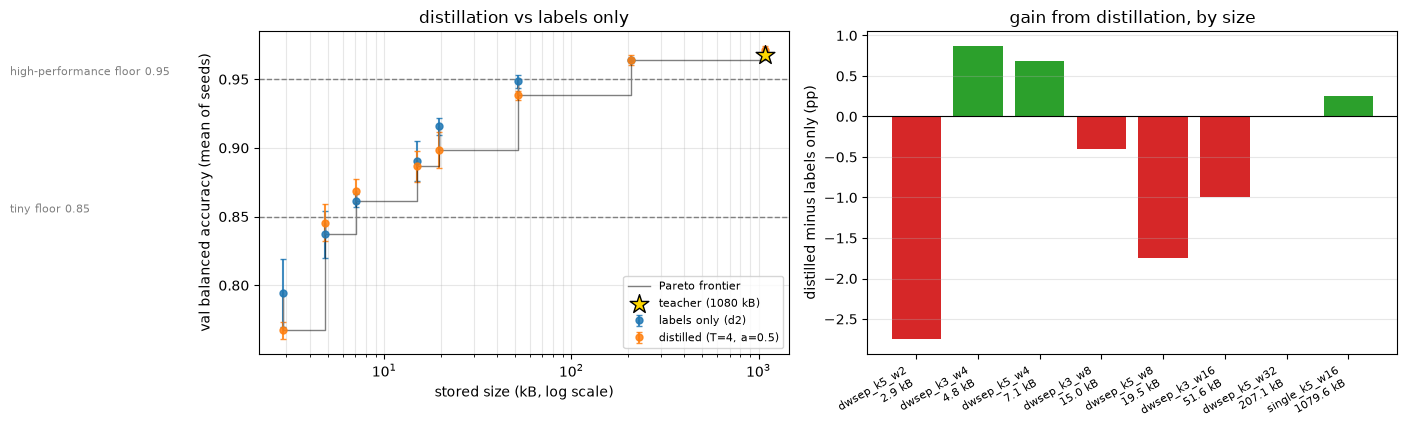

In [3]:
kd = {}
for a in FRONT:
    cfg = replace(arch_cfg(a, "d3", f"{a['name']}_kdT{KD['T']}a{KD['alpha']}"), extra={"kd": KD})
    kd[a["name"]] = R.run_seeds(cfg)
tk, tl = R.table(kd), R.table(plain)
cmp = pd.DataFrame({"kB": tl.kB, "labels only": tl.bal_acc, "distilled": tk.bal_acc,
                    "gain (pp)": (tk.bal_acc.astype(float) - tl.bal_acc.astype(float)) * 100,
                    "sd labels": tl.sd, "sd distilled": tk.sd}).sort_values("kB")
# paired by seed: same seed, same initialisation and data order; only the loss differs
cmp["seeds improved"] = [sum(k["val"]["bal_acc"] > p["val"]["bal_acc"] for k, p in zip(kd[n], plain[n])) for n in cmp.index]
display(cmp.round(4))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
R.tradeoff_plot({"labels only (d2)": tl, f"distilled (T={KD['T']}, a={KD['alpha']})": tk}, "distillation vs labels only",
                ax=ax[0], teacher_acc=json.loads((ARTIFACTS / "compress_rules.json").read_text())["teacher"]["bal_acc"])
for n in cmp.index:
    ax[0].plot([tl.loc[n, "kB"]] * 2, [tl.loc[n, "bal_acc"], tk.loc[n, "bal_acc"]], color="grey", lw=0.8)
ax[1].bar(range(len(cmp)), cmp["gain (pp)"], color=["C2" if g > 0 else "C3" for g in cmp["gain (pp)"]])
ax[1].set_xticks(range(len(cmp)), [f"{n}\n{kb:.1f} kB" for n, kb in zip(cmp.index, cmp.kB)], rotation=30, ha="right", fontsize=8)
ax[1].axhline(0, color="k", lw=0.8); ax[1].set(ylabel="distilled minus labels only (pp)", title="gain from distillation, by size")
ax[1].grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

**Result: distillation does not reliably help here.** It beats labels-only for 3 of the 8 architectures, by
+0.3 to +0.9 pp, ties for 1 (w32, −0.01 pp) and loses for 4, by up to 2.8 pp (dw-sep 5x5 w2, 0 of 3 seeds improved) and 1.8 pp (dw-sep 5x5
w8, 0 of 3). Most differences are within one or two seed sds. There is no trend with size: neither the smallest
nor the largest students gain systematically.

**Why so little?** The textbook gain from distillation comes from the teacher's "dark knowledge": the relative
probabilities it gives the wrong classes. Two things limit that here:
* **The teacher was trained with label smoothing** (chosen in c6). Label smoothing pushes all wrong-class
  probabilities towards the same value, which erases much of the class-similarity information distillation
  transfers (Müller, Kornblith & Hinton 2019, *When does label smoothing help?*).
* **The task leaves little to transfer.** With 4 classes and a teacher at 0.97, the soft targets mostly repeat
  the labels; the one structured confusion (glioma vs meningioma) is something the students already learn.

The one consistent gain is **self-distillation** of the teacher's own architecture (0.969 to 0.971, 3 of 3 seeds),
a known effect, but it does not make anything smaller.

A teacher trained without label smoothing might distil better. **In hindsight, choosing label smoothing for the
teacher was most likely a mistake**, since distillation was planned from the start: in c6 it won by only 0.03 pp
over plain cross-entropy, so it bought the teacher nothing while probably costing the students their gain. Not
tested.

## 3. Decision: how each student is trained from here on

In [4]:
best_student = {n: ("distilled" if float(tk.loc[n, "bal_acc"]) > float(tl.loc[n, "bal_acc"]) else "labels only") for n in cmp.index}
out = [{**a, "method": best_student[a["name"]], "kd": KD if best_student[a["name"]] == "distilled" else None,
        "run": f"d3/{a['name']}_kdT{KD['T']}a{KD['alpha']}" if best_student[a["name"]] == "distilled"
               else (f"d2/{a['name']}" if a["name"] != TEACHER_ARCH else None),
        "bal_acc": float(max(tk.loc[a["name"], "bal_acc"], tl.loc[a["name"], "bal_acc"])),
        "bytes": int(tl.loc[a["name"], "bytes"])} for a in FRONT]
_ = (ARTIFACTS / "d3_students.json").write_text(json.dumps({"kd": KD, "students": out}, indent=1))
pd.DataFrame(out)[["name", "method", "bytes", "bal_acc"]]

,name,method,bytes,bal_acc
0,dwsep_k5_w32,labels only,212112,0.9643
1,dwsep_k5_w8,labels only,20016,0.9158
2,dwsep_k5_w4,distilled,7264,0.8685
3,dwsep_k5_w2,labels only,2952,0.7946
4,dwsep_k3_w16,labels only,52816,0.9484
5,dwsep_k3_w8,labels only,15408,0.8906
6,dwsep_k3_w4,distilled,4960,0.8457
7,single_k5_w16,distilled,1105488,0.9710


**Decision.** Each architecture keeps the training method with the higher mean: distilled for dw-sep 3x3 w4,
dw-sep 5x5 w4 and the teacher layout, labels only for the other five. These are the starting points for pruning
(d4). Distillation stays in the fine-tuning of a pruned or quantized model only if that model was distilled.